In [1]:
import xarray as xr

In [5]:
%cd /g/data/w42/dr6273/work/wind_drought

/g/data/w42/dr6273/work/wind_drought


In [7]:
import src.wind as wind

In [16]:
# Grid wind/capacity factor
ds = xr.open_dataset(
    "/g/data/ng72/dr6273/work/projects/wind_drought/data/ERA5/power_grid/era5_wind_speed_100m_SC30_1979-2025_equal.nc",
)

In [17]:
da = ds.wind_speed

In [18]:
da

<xarray.DataArray 'wind_speed' (time: 17167)> Size: 137kB
[17167 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 137kB 1979-01-01 1979-01-02 ... 2025-12-31
Attributes:
    units:    m s**-1

In [31]:
QUANTILE = 0.1

In [36]:
thresh = da.isel(time=da.time.dt.month.isin([5,6,7])).quantile(QUANTILE, "time")
thresh

<xarray.DataArray 'wind_speed' ()> Size: 8B
array(3.67025835)
Coordinates:
    quantile  float64 8B 0.1
Attributes:
    units:    m s**-1

In [37]:
events = wind.calc_wdd_timeseries(da, thresh)

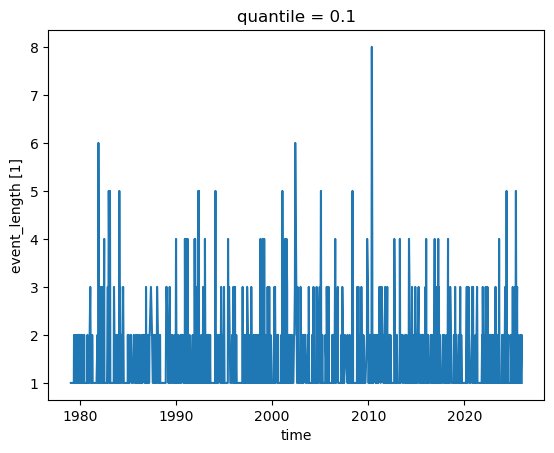

In [38]:
events.event_length.plot()